<a href="https://colab.research.google.com/github/RyanO14/ENGPHYS-2NM4/blob/main/Assignments/Assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 4

## Q1. The Blasius equation appears in fluid mechanics as a laminar flow boundary layer and is written:

$$y^{\prime\prime\prime} + y y^{\prime\prime} = 0 $$

### a) Express this 3rd order ODE as a system of first order ODEs.

$$ y_1' = y_2 \\ y_2' =y_3 \\ y_3' = -y_1 y_3$$

### b) Solve for $y(z)$ as an initial value problem assuming the boundary conditions below and plot the answer:

$$
\begin{align}
y(z=0) &= 0 \\
y^\prime(z=0) &= 0 \\
y^{\prime\prime}(z = 0) &= 1 \\
\end{align}
$$

HINT: Read and consider part c) before implementing this.

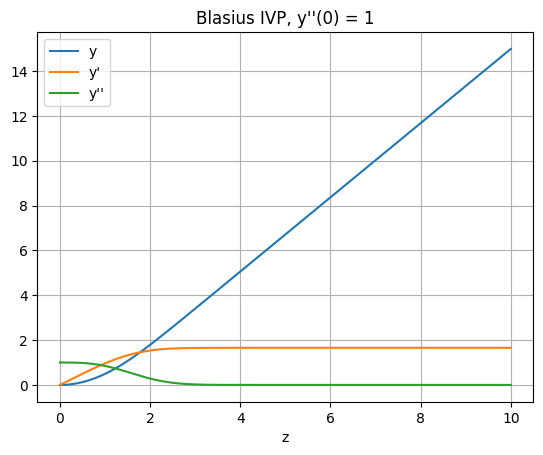

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def blasius(z, s):
  y, yp, ypp = s
  return [yp, ypp, -y*ypp]

z_span = (0, 10)
z_eval = np.linspace(*z_span, 400)
s0 = [0, 0, 1]

sol = solve_ivp(blasius, z_span, s0, t_eval=z_eval, method='RK45', rtol=1e-10, atol=1e-10)

plt.plot(sol.t, sol.y[0], label='y')
plt.plot(sol.t, sol.y[1], label='y\'')
plt.plot(sol.t, sol.y[2], label='y\'\'')
plt.xlabel('z')
plt.legend()
plt.grid()
plt.title("Blasius IVP, y''(0) = 1")
plt.show()

$$
\begin{array}{l}
\text{With } y''(0)=1\text{, } y' \text{ rises from 0 and levels off at about } 1.655 \text{ by } z=10. \\
\text{This is short of the target } y'(\infty)=2 \text{ in part c.} \\
\text{This is why part c wraps the same function in a shooting loop.} \\
\text{A root finder adjusts } y''(0) \text{ until } y'(10)=2\text{, which gives } y''(0)\approx 1.328.
\end{array}
$$

## c) Use your *method* from b) to find a value of $y''(z=0)$ such that $y(z)$ fits the boundary conditions below, and plot the answer:

$$
\begin{align}
y(z=0) &= 0 \\
y^\prime(z=0) &= 0 \\
y^{\prime}(z = \infty) &= 2 \\
\end{align}
$$



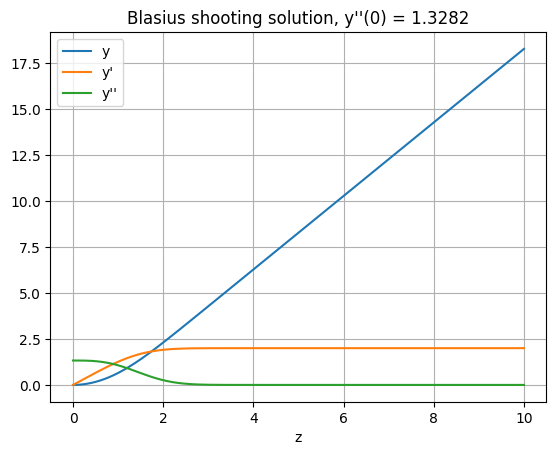

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt

def blasius(z, s):
    y, yp, ypp = s
    return [yp, ypp, -y*ypp]

z_end = 10
def residual(s2):
    sol = solve_ivp(blasius, (0, z_end), [0, 0, s2], rtol=1e-10, atol=1e-10)
    return sol.y[1, -1] - 2

root = root_scalar(residual, bracket=[0.1, 5], method='brentq')
s2 = root.root                      # 1.3282

z = np.linspace(0, z_end, 400)
sol = solve_ivp(blasius, (0, z_end), [0, 0, s2], t_eval=z, rtol=1e-10, atol=1e-10)

plt.plot(z, sol.y[0], label="y")
plt.plot(z, sol.y[1], label="y'")
plt.plot(z, sol.y[2], label="y''")
plt.xlabel("z"); plt.legend(); plt.grid()
plt.title(f"Blasius shooting solution, y''(0) = {s2:.4f}")
plt.show()

Method:
- Treat s = y"(0) as the unknown,
- Integrate the part b system from [0, 0, s] to a large z (10) as a an infinity equivalent,
- Define the residual F(s) = y'(10; s) - 2,
- Use a root finder to solve F(s) = 0. In this case Brent's method was used on [0.1, 5].

y"(0) = ~1.3282. This value makes y' approach 2 at the far boundary.

## Q2

The Fourier series shows that periodic functions can be written as an infinite sum of sine and cosine waves:

 $$f(x)= \frac{A_0}{2}+\sum_{n=1}^{\infty}A_n\ \cos{(nx)} + B_n\ \sin{(nx)}$$

Due to function orthogonality, the values of $A_n$ and $B_n$ can be computed using the following formulae:

 $$A_n= \frac{1}{\pi} \int_{-\pi}^{\pi} f(x) \cos{(nx)}\ dx$$
 $$B_n= \frac{1}{\pi} \int_{-\pi}^{\pi} f(x) \sin{(nx)}\ dx$$

Periodic functions can be approximated by truncating the Fourier series at some $n = N$.

### 2a

Write a function that takes a $2-\pi$ periodic function and a degree $n$, then outputs the $n-th$ Fourier coefficients $[A_n, B_n]$. Use the equations above with a suitable integration method. (Don't use packaged Fourier analysis tools)

Test it for a suitable set of functions for which you have an analytic answer.

E.g.: f(x) = sin(3x) + 2cos(x) would have:

| **n** | **A** | **B** |
|---|---|---|
| **0** | 0 | 0 |
| **1** | 2 | 0 |
| **2** | 0 | 0 |
| **3** | 0 | 1 |



In [6]:
import numpy as np
from scipy.integrate import quad

# 2a
def fourier_coeffs(f, n, nseg=8):
    pts = np.linspace(-np.pi, np.pi, nseg + 1)
    def integral(h):
        return sum(quad(h, a, b, limit=400)[0] for a, b in zip(pts[:-1], pts[1:])) / np.pi
    A = integral(lambda x: f(x) * np.cos(n * x))
    B = integral(lambda x: f(x) * np.sin(n * x)) if n > 0 else 0.0
    return A, B

def table(f, N):
    print(f"{'n':>3} {'A':>9} {'B':>9}")
    for n in range(N + 1):
        A, B = fourier_coeffs(f, n)
        print(f"{n:>3} {A:>9.4f} {B:>9.4f}")

# 2a test: expect (0,0), (2,0), (0,0), (0,1)
table(lambda x: np.sin(3*x) + 2*np.cos(x), 3)

# 2b
cases = [
    (lambda x: np.mod(x, np.pi/2), 5),
    (lambda x: np.mod(x, np.pi/2), 20),
    (lambda x: (x > -np.pi/2) & (x < np.pi/2), 2),
    (lambda x: (x > -np.pi/2) & (x < np.pi/2), 20),
]
for f, N in cases:
    print(f"\nN = {N}")
    table(lambda x, f=f: np.float64(f(x)), N)

  n         A         B
  0    0.0000    0.0000
  1    2.0000   -0.0000
  2    0.0000    0.0000
  3    0.0000    1.0000

N = 5
  n         A         B
  0    1.5708    0.0000
  1    0.0000   -0.0000
  2   -0.0000   -0.0000
  3   -0.0000    0.0000
  4   -0.0000   -0.5000
  5    0.0000   -0.0000

N = 20
  n         A         B
  0    1.5708    0.0000
  1    0.0000   -0.0000
  2   -0.0000   -0.0000
  3   -0.0000    0.0000
  4   -0.0000   -0.5000
  5    0.0000   -0.0000
  6   -0.0000   -0.0000
  7    0.0000    0.0000
  8   -0.0000   -0.2500
  9    0.0000    0.0000
 10   -0.0000   -0.0000
 11   -0.0000    0.0000
 12   -0.0000   -0.1667
 13    0.0000   -0.0000
 14   -0.0000   -0.0000
 15    0.0000    0.0000
 16   -0.0000   -0.1250
 17    0.0000   -0.0000
 18   -0.0000    0.0000
 19    0.0000    0.0000
 20   -0.0000   -0.1000

N = 2
  n         A         B
  0    1.0000    0.0000
  1    0.6366    0.0000
  2    0.0000    0.0000

N = 20
  n         A         B
  0    1.0000    0.0000
  1    0.6

It can be noted that the produced table matches the analytic table in the question. Here the constant term in the series is A0/2.

### 2b
Find the coefficients of the following functions and expansion orders:


In [ ]:
f = lambda x: np.mod(x, np.pi/2)
N = 5

In [ ]:
f = lambda x: np.mod(x, np.pi/2)
N = 20

In [ ]:
f = lambda x: (x > -np.pi/2) & (x < np.pi/2)
N = 2

In [ ]:
f = lambda x: (x > -np.pi/2) & (x < np.pi/2)
N = 20

All answers above.

## Q3:

Given $$\int_{-1}^1 f(x) dx = 3$$ and $$f(-3^{-\frac{1}{2}}) = 1$$

Assuming $f$ is a cubic polynomial, what is $f(3^{-\frac{1}{2}})$? Why?



$$f(3^{-1/2}) = 2 $$

Two-point Gauss-Legendre quadrature is exact for cubics, so the integral fixes the sum of f at its two nodes.

For a cubic f:
$$ \int_{-1}^1f(x)dx = f(\frac{1}{\sqrt3})+f(\frac{-1}{\sqrt3}) $$

Substuting values gives:
$$3 = 1 + f(\frac{1}{\sqrt3}) $$

Thus:
$$f(\frac{1}{\sqrt3}) = 2$$

For a cubic, the odd terms bx and dx^3 integrate to 0 over [-1, 1] and the Gauss nodes also cancle them. That leaves 2a + (2/3)c as the integral. The node sum is f(-x0) + f(x0) = 2a 2cx0^2. With x0^2 = 1/3, this equals 2a + (2/3)c. The two sides match, which is why the answer doesn't depend on unknown coeffcients.

In [9]:
import numpy as np
from scipy.integrate import quad

x0 = 1/np.sqrt(3)

a, d = 0.4, -1.3            # free choices
c = 3*(1.5 - a)             # from a + c/3 = 1.5
b = 0.5/x0 - d/3            # from b + d/3 = 0.5/x0

f = lambda x: a + b*x + c*x**2 + d*x**3

print("integral:", quad(f, -1, 1)[0])   # 3.0
print("f(-1/√3):", f(-x0))              # 1.0
print("f(+1/√3):", f(x0))               # 2.0

integral: 2.9999999999999996
f(-1/√3): 1.0000000000000004
f(+1/√3): 2.0000000000000004
